# Week 3: Data Visualization, Feature Engineering, and Selection
**September 28 · Gina and Samarth**

In [Week 2](pandas-cleaning-and-eda.ipynb), we introduced pandas, cleaning, and exploratory data analysis. This week uses charts to explore patterns, then introduces features, encoding, and input selection. These are complete worked examples; practice the ideas in Lab 02.

1. Visualize numerical distributions, categories, and relationships.
2. Create features and encode categorical variables.
3. Select inputs that are available at prediction time.

For later modeling work, see [Week 7](unsupervised-learning.ipynb) for feature scaling and the difference between feature selection and extraction.


## Data Visualization

### Why do we need to visualize data?

EDA makes heavy use of visualizations, which have a key role in both *uncovering* useful observations and later *communicating* those findings to others.

Consider the following image as an example for why EDA and data visualization are necessary.

![Plots with identical summary statistics and different shapes](same-summary-statistics.png)

All visualizations have the same summary statistics (mean, SD, etc.), but they clearly convey very different information! Using visualizations and EDA can reveal details from data that cannot be understood from numerical values alone.


### Common Types of Visualizations

Visualizations are plotted using Matplotlib and Seaborn. Matplotlib lets you customize your plots with greater detail, but Seaborn allows you to easily make more visually appealing plots.

Matplotlib is usually imported as `plt`, while Seaborn is usually imported as `sns`.

I'm creating a `tas` dataframe that will be used for the demos in the code cell below.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

raw_data = {
    "Student ID":    [101, 102, 103, 104, 105, 106, 107, 108, 109, 102],
    "Name":      ["Gina", "Iana", "Kabilan", "Nathan", "Earn", None, "Sameer", "Sarah", "Wayland", "Iana"],
    "Major":         ["Math", "DS", "Math", "DS", "Business", "DS", "economics", "CS", "DS", "Biology"],
    "GPA":           [3.8, 3.7, 3.9, 3.0, 3.6, 3.2, None, 3.1, 3.7, 3.5],
    "Year":          [2, 3, 1, 4, 2, 3, 1, 3, 4, 3],
    "scholarship":   ["yes", "no", "yes", "no", "yes", "no", "yes", "no", None, "no"],
    "Extra Column":  [None] * 10
}
tas = pd.DataFrame(raw_data)
tas

Matplotlib is building the font cache; this may take a moment.


,Student ID,Name,Major,GPA,Year,scholarship,Extra Column
0,101,Gina,Math,3.8,2,yes,None
1,102,Iana,DS,3.7,3,no,None
2,103,Kabilan,Math,3.9,1,yes,None
3,104,Nathan,DS,3.0,4,no,None
4,105,Earn,Business,3.6,2,yes,None
5,106,NaN,DS,3.2,3,no,None
6,107,Sameer,economics,NaN,1,yes,None
7,108,Sarah,CS,3.1,3,no,None
8,109,Wayland,DS,3.7,4,NaN,None
9,102,Iana,Biology,3.5,3,no,None


### Histograms
Histograms visualize the distribution of a single *quantitative* variable.

To plot a histogram in Matplotlib, use the structure `plt.hist(x)` where `x` is a series. There are many other optional arguments you can pass into the `plt.hist()` function, and you can read more about them [here](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html) in the matplotlib documentation.

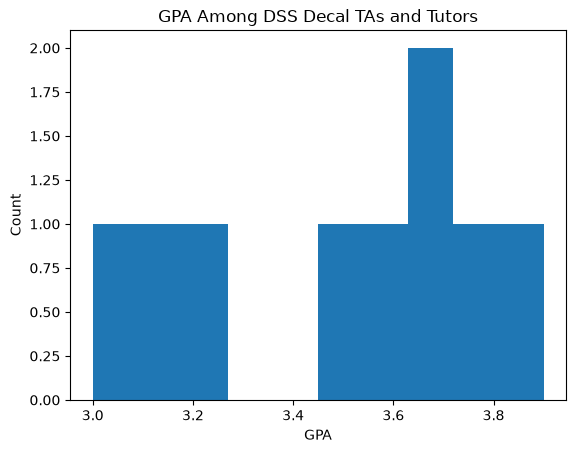

In [2]:
plt.figure()
x = tas['GPA']
plt.hist(x)

# Add labels
plt.xlabel("GPA")
plt.ylabel("Count")
plt.title("GPA Among DSS Decal TAs and Tutors");
plt.show()


### Bar Plots
A bar plot visualizes the distribution of a qualitative (categorical) variable. The length of a bar plot encodes the frequency of a category.

To plot bar plots in Matplotlib, use the structure `plt.bar(x, height)` where `x` is an array / series / index of the category labels and `height` is an array / series / index of the height for each bar (usually counts).

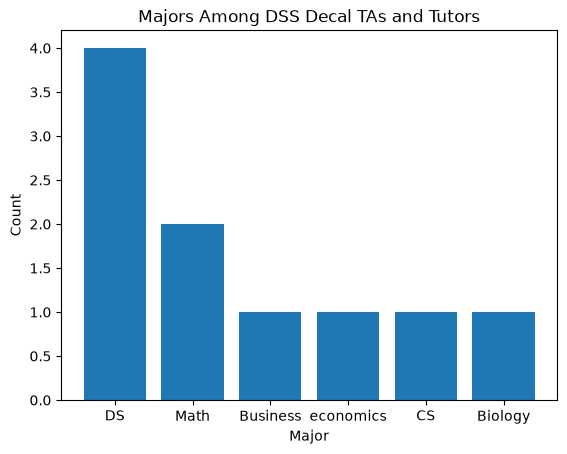

In [3]:
plt.figure()
x = tas['Major'].value_counts()
plt.bar(x.index, x);

# Add labels
plt.xlabel("Major")
plt.ylabel("Count")
plt.title("Majors Among DSS Decal TAs and Tutors");
plt.show()


### Scatter Plot
Scatter plots visualize the relationship between pairs of quantitative variables. They indicate the strength, or correlation, of the relationship between variables.

To plot scatterplots in Matplotlib, use the structure `plt.scatter(x, y)` where `x` is an array / series / index of the x-axis variable and `y` is an array / series / index of y-axis variable.

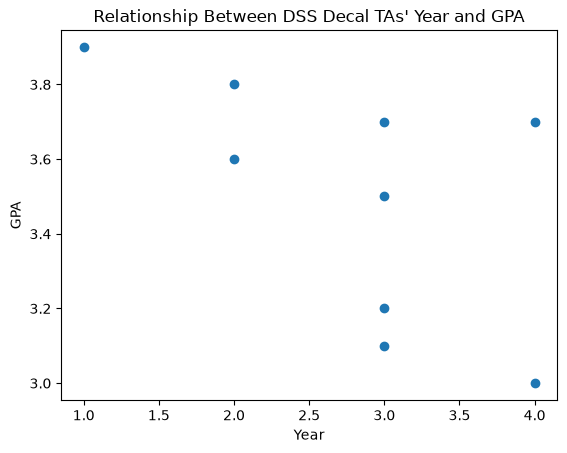

In [4]:
plt.figure()
year = tas['Year']
gpa = tas['GPA']
plt.scatter(year, gpa);

# Add labels
plt.xlabel("Year")
plt.ylabel("GPA")
plt.title("Relationship Between DSS Decal TAs' Year and GPA");
plt.show()


### Line Plots
Line plots visualize how a single *quantitative* variable changes over time.

To plot line plots in Matplotlib, use the structure `plt.plot(x, y)` where `x` is an array / series / index of the x-axis variable and `y` is an array / series / index of y-axis variable.

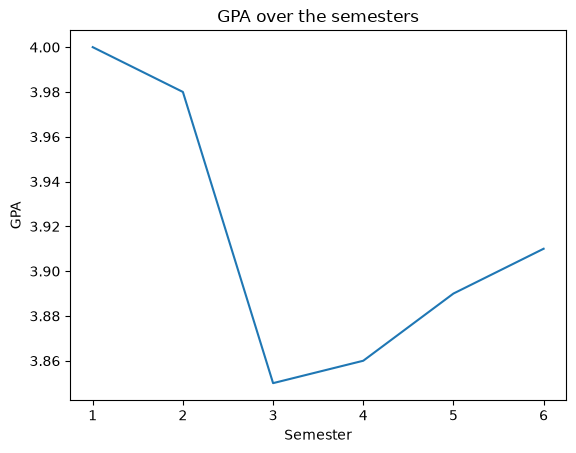

In [5]:
plt.figure()
raw_data = {
    "Semester":      [1, 2, 3, 4, 5, 6],
    "GPA":           [4.00, 3.98, 3.85, 3.86, 3.89, 3.91],
}
gpa_df = pd.DataFrame(raw_data)

plt.plot(gpa_df['Semester'], gpa_df['GPA']);

# Add labels
plt.xlabel("Semester")
plt.ylabel("GPA")
plt.title("GPA over the semesters");
plt.show()


### Count Plots and Box Plots

A Seaborn count plot counts rows in each category, like the bar chart above. A box plot compares a numerical distribution across categories: the central line is the median and the box spans the middle half of the observations. Points beyond the whiskers are not automatically errors.

These small example tables are for demonstration. Counts describe the observed rows, not the popularity of a major, and a scatterplot alone cannot establish cause and effect.


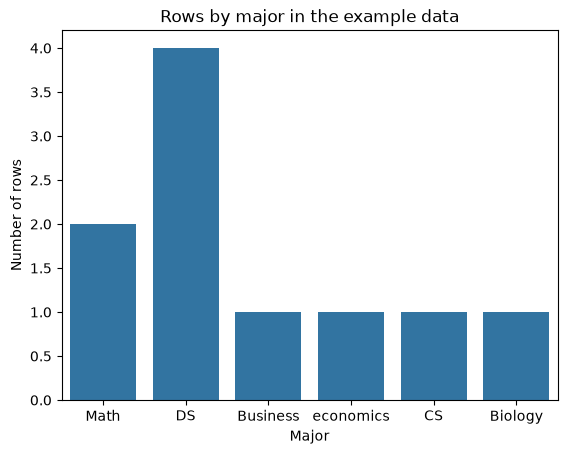

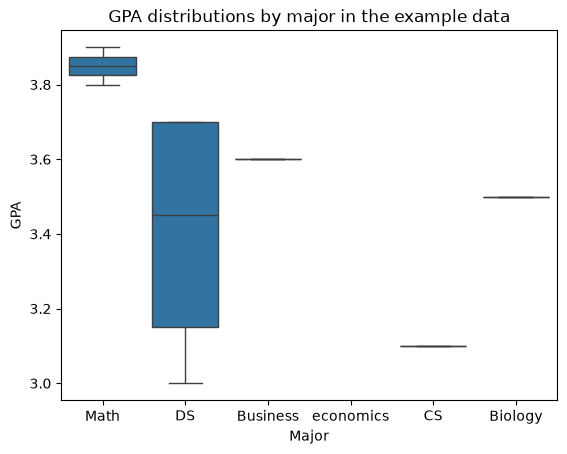

In [6]:
plt.figure()
sns.countplot(data=tas, x="Major")
plt.title("Rows by major in the example data")
plt.xlabel("Major")
plt.ylabel("Number of rows")
plt.show()

plt.figure()
sns.boxplot(data=tas, x="Major", y="GPA")
plt.title("GPA distributions by major in the example data")
plt.xlabel("Major")
plt.ylabel("GPA")
plt.show()


## Feature Engineering

### What is Feature Engineering?

Feature engineering is the process of transforming raw data into meaningful inputs (called features) that machine learning models can use more effectively. Instead of feeding a model the dataset exactly as it was collected, we often modify existing variables, combine multiple variables, or create entirely new ones that better capture patterns in the data.

For example, a dataset might contain a person's date of birth, but a model may learn more effectively from a derived feature like age. Similarly, combining variables such as price and quantity into a new feature like total spending can help a model capture relationships that are not immediately visible in the original data.

Feature engineering plays an important role in both model performance and interpretability. Well-designed features help models detect meaningful patterns more easily, which can improve predictive accuracy. At the same time, features that represent clear real-world concepts make it easier for humans to understand how and why a model arrives at its predictions.

Because of this, feature engineering is often one of the most impactful steps in the data science workflow. In many cases, improving the features used by a model can lead to larger performance gains than simply switching to a more complex algorithm.

### Why is Feature Engineering Important?

Machine learning models do not learn directly from raw data, but rather they learn from the features we provide. The quality and structure of these features strongly influence how well a model can detect patterns and make predictions.

If the features capture the important relationships in the data, even relatively simple models can perform well. However, if the features are poorly constructed or fail to represent meaningful information, even advanced models may struggle to learn useful patterns.

This idea is often summarized by the principle “Garbage In, Garbage Out” (GIGO). A model's prediction is only as good as the data we put inside of it, so the feature engineering phase is critical to creating a good model.

By carefully designing and transforming features, we make it easier for models to understand the underlying structure of the data. As a result, good feature engineering can lead to more accurate models, faster training, and more interpretable predictions.

### Encoding Categorical Variables

Variables in a dataset generally fall into two categories: quantitative and categorical. Quantitative variables represent numerical values that have meaningful magnitudes, such as age, income, or temperature. Categorical variables represent discrete groups or labels, such as color, country, or type of product.

Most machine learning models require numerical inputs, which means categorical variables must be converted into numbers before a model can use them. This process is called encoding.

It is important that the encoding method preserves the meaning of the categories without introducing misleading relationships. For example, assigning numbers like 1, 2, and 3 to categories such as red, blue, and green might incorrectly suggest an ordering between them. Instead, techniques like one-hot encoding create separate binary columns for each category, allowing models to represent categories without implying a numerical relationship.

### One-hot Encoding vs Ordinal Encoding

Two common methods for converting categorical variables into numerical form are one-hot encoding and ordinal encoding. Each method is appropriate for different types of categorical data.


#### Ordinal Encoding

Ordinal encoding assigns an integer value to each category. This method is appropriate when the categories have a natural order.

For example, education levels such as High School, Bachelor’s, and Master’s have an inherent ranking. Encoding them as 0, 1, 2 preserves this ordering.

In [7]:
import pandas as pd

df = pd.DataFrame({
    "education": ["High School", "Bachelors", "Masters", "Bachelors"]
})

mapping = {
    "High School": 0,
    "Bachelors": 1,
    "Masters": 2
}

df["education_encoded"] = df["education"].map(mapping)

df

,education,education_encoded
0,High School,0
1,Bachelors,1
2,Masters,2
3,Bachelors,1


Here, the model can learn from the fact that Master’s > Bachelor’s > High School.

However, ordinal encoding should not be used when categories have no meaningful order.

#### One-hot Encoding

One-hot encoding creates a separate binary column for each category. A value of 1 indicates the presence of that category, while 0 indicates absence.

This method is appropriate for nominal categorical variables, where categories do not have an inherent order (e.g., colors or product types).

Here's an example:

In [8]:
df = pd.DataFrame({
    "color": ["red", "blue", "green", "blue"]
})

df_encoded = pd.get_dummies(df, columns=["color"], dtype=int)

df_encoded

,color_blue,color_green,color_red
0,0,0,1
1,1,0,0
2,0,1,0
3,1,0,0


This produces columns like:

color_blue,           color_green, and           color_red

Each row will have a 1 in the column corresponding to its category.

### What is Feature Selection?

Feature selection is the process of identifying and selecting the most relevant features in a dataset to use when training a machine learning model. Instead of using every available variable, feature selection focuses on keeping the features that provide useful information while removing those that are irrelevant, redundant, or noisy.

Feature selection is important because unnecessary features can make models more complex, harder to interpret, and more prone to overfitting. By reducing the number of features, we can simplify the model, improve interpretability, and sometimes even improve predictive performance. Additionally, using fewer features can reduce computational cost and make models faster to train.

#### Choose inputs available at prediction time

First specify what you want to predict (the **target**) and when you will make that prediction. Keep the target out of the input table. Avoid information that will only become available after the outcome: this is **data leakage**.

For example, to predict a delivery's duration when an order is placed, distance and whether it is a weekend may be available. The actual arrival time is not. This small example creates a Boolean feature and selects inputs without training a model.


In [9]:
deliveries = pd.DataFrame({
    "distance_km": [1.5, 4.0, 2.0, 6.0],
    "day": ["Monday", "Saturday", "Sunday", "Tuesday"],
    "duration_minutes": [15, 32, 20, 45],
})
deliveries["weekend"] = deliveries["day"].isin(["Saturday", "Sunday"])
X = deliveries[["distance_km", "weekend"]]
y = deliveries["duration_minutes"]
X


,distance_km,weekend
0,1.5,False
1,4.0,True
2,2.0,True
3,6.0,False


## Recap

Use a histogram for a numerical distribution, a count plot for category frequencies, a scatterplot for two numerical variables, and a box plot to compare distributions across groups. Label axes and distinguish observed associations from causal claims.

Feature engineering creates or transforms inputs; feature selection chooses which to keep. One-hot encoding represents unordered categories without implying a rank. Keep the target separate and use only information available at prediction time.

Continue with [Week 7](unsupervised-learning.ipynb) for feature scaling and dimensionality reduction.
